In [ ]:
!pip install -q wfdb PyWavelets scipy scikit-learn matplotlib pandas pillow streamlit langgraph faiss-cpu


In [ ]:
import os

PROJECT = "/content/ECG_project"
os.makedirs(PROJECT, exist_ok=True)

print("Project folder:", PROJECT)
print("Folder created:", os.path.exists(PROJECT))

Project folder: /content/ECG_project
Folder created: True


In [ ]:
!pip install -q wfdb PyWavelets scipy scikit-learn matplotlib pandas pillow streamlit langgraph faiss-cpu

In [ ]:
import os

print(os.path.exists("/content/prepare_data.py"))

False


In [ ]:

%%writefile /content/prepare_data.py
import os
import wfdb
import numpy as np
import pywt

from scipy.signal import butter, filtfilt, resample
from collections import Counter

PROJECT = "/content/ECG_project"

RECORDS = ["100", "101", "105", "106", "108", "109"]

CLASS_MAP = {
    "N": 0, "L": 0, "R": 0, "e": 0, "j": 0,
    "V": 1, "E": 1,
    "A": 2, "a": 2, "J": 2, "S": 2
}

def preprocess(signal, fs):
    low = 0.5 / (fs / 2)
    high = min(40 / (fs / 2), 0.99)
    b, a = butter(3, [low, high], btype="band")
    return filtfilt(b, a, signal)

def main():
    signals = []
    scalograms = []
    labels = []

    for rid in RECORDS:
        print("Processing record:", rid, flush=True)

        record = wfdb.rdrecord(rid, pn_dir="mitdb")
        ann = wfdb.rdann(rid, "atr", pn_dir="mitdb")

        ecg = preprocess(record.p_signal[:, 0], record.fs)
        half = int(record.fs * 0.5)

        for sample, symbol in zip(ann.sample, ann.symbol):
            if symbol not in CLASS_MAP:
                continue

            if sample - half < 0 or sample + half >= len(ecg):
                continue

            beat = ecg[sample-half:sample+half]
            beat = resample(beat, 128).astype(np.float32)
            beat = (beat - beat.mean()) / (beat.std() + 1e-8)

            coeffs, _ = pywt.cwt(
                beat, np.arange(1, 17), "morl"
            )

            image = np.abs(coeffs)
            rows = np.linspace(0, image.shape[0]-1, 64).astype(int)
            cols = np.linspace(0, image.shape[1]-1, 64).astype(int)
            image = image[np.ix_(rows, cols)].astype(np.float32)
            image /= image.max() + 1e-8

            signals.append(beat)
            scalograms.append(image)
            labels.append(CLASS_MAP[symbol])

    signals = np.asarray(signals, dtype=np.float32)
    scalograms = np.asarray(scalograms, dtype=np.float32)
    labels = np.asarray(labels, dtype=np.int64)

    output = os.path.join(PROJECT, "beats.npz")
    np.savez_compressed(
        output,
        signals=signals,
        scalograms=scalograms,
        labels=labels
    )

    print("\nDataset saved:", output)
    print("Signals shape:", signals.shape)
    print("Scalograms shape:", scalograms.shape)
    print("Class counts:", Counter(labels.tolist()))

if __name__ == "__main__":
    main()


Writing /content/prepare_data.py


In [ ]:
!python -u /content/prepare_data.py

Processing record: 100
Processing record: 101
Processing record: 105
Processing record: 106
Processing record: 108
Processing record: 109

Dataset saved: /content/ECG_project/beats.npz
Signals shape: (13015, 128)
Scalograms shape: (13015, 64, 64)
Class counts: Counter({0: 12358, 1: 617, 2: 40})


In [ ]:
import numpy as np
from sklearn.model_selection import train_test_split
from collections import Counter

data = np.load("/content/ECG_project/beats.npz")

signals = data["signals"]
scalograms = data["scalograms"]
labels = data["labels"]

X_train, X_test, S_train, S_test, y_train, y_test = train_test_split(
    signals,
    scalograms,
    labels,
    test_size=0.2,
    random_state=42,
    stratify=labels
)

print("Training samples:", len(y_train))
print("Testing samples:", len(y_test))
print("Training classes:", Counter(y_train))
print("Testing classes:", Counter(y_test))

Training samples: 10412
Testing samples: 2603
Training classes: Counter({np.int64(0): 9886, np.int64(1): 494, np.int64(2): 32})
Testing classes: Counter({np.int64(0): 2472, np.int64(1): 123, np.int64(2): 8})


In [ ]:

import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader
from sklearn.utils.class_weight import compute_class_weight
import numpy as np

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)

# Convert data into PyTorch tensors
Xtr = torch.tensor(X_train, dtype=torch.float32).unsqueeze(1)
Xte = torch.tensor(X_test, dtype=torch.float32).unsqueeze(1)

ytr = torch.tensor(y_train, dtype=torch.long)
yte = torch.tensor(y_test, dtype=torch.long)

train_loader = DataLoader(
    TensorDataset(Xtr, ytr),
    batch_size=128,
    shuffle=True
)

# Define 1D CNN
class ECGSignalCNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv1d(1, 16, kernel_size=7, padding=3),
            nn.ReLU(),
            nn.MaxPool1d(2),
            nn.Conv1d(16, 32, kernel_size=5, padding=2),
            nn.ReLU(),
            nn.MaxPool1d(2),
            nn.AdaptiveAvgPool1d(1)
        )
        self.classifier = nn.Linear(32, 3)

    def forward(self, x):
        x = self.features(x).squeeze(-1)
        return self.classifier(x)

model = ECGSignalCNN().to(device)

# Give more weight to underrepresented classes
classes = np.unique(y_train)
weights = compute_class_weight(
    class_weight="balanced",
    classes=classes,
    y=y_train
)

weights = torch.tensor(weights, dtype=torch.float32).to(device)

criterion = nn.CrossEntropyLoss(weight=weights)
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)

# Train for 3 epochs
for epoch in range(3):
    model.train()
    total_loss = 0

    for xb, yb in train_loader:
        xb, yb = xb.to(device), yb.to(device)

        optimizer.zero_grad()
        outputs = model(xb)
        loss = criterion(outputs, yb)
        loss.backward()
        optimizer.step()

        total_loss += loss.item()

    print(
        f"Epoch {epoch+1}/3 | "
        f"Loss: {total_loss / len(train_loader):.4f}"
    )

print("Training completed!")


Using device: cpu
Epoch 1/3 | Loss: 1.0108
Epoch 2/3 | Loss: 0.9020
Epoch 3/3 | Loss: 0.7802
Training completed!


In [ ]:
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

model.eval()

with torch.no_grad():
    predictions = model(Xte.to(device)).argmax(dim=1).cpu().numpy()

print("Test Accuracy:", round(accuracy_score(y_test, predictions), 4))

print("\nClassification Report:")
print(classification_report(
    y_test,
    predictions,
    labels=[0, 1, 2],
    target_names=[
        "Normal",
        "Ventricular",
        "Supraventricular"
    ],
    zero_division=0
))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, predictions, labels=[0, 1, 2]))

Test Accuracy: 0.6708

Classification Report:
                  precision    recall  f1-score   support

          Normal       0.99      0.66      0.79      2472
     Ventricular       0.12      0.91      0.21       123
Supraventricular       0.00      0.00      0.00         8

        accuracy                           0.67      2603
       macro avg       0.37      0.52      0.33      2603
    weighted avg       0.94      0.67      0.76      2603


Confusion Matrix:
[[1634  838    0]
 [  11  112    0]
 [   7    1    0]]


In [ ]:

import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader
from sklearn.utils.class_weight import compute_class_weight
import numpy as np

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)

# Convert scalograms to (samples, channels, height, width)
Xtr_img = torch.tensor(S_train, dtype=torch.float32).unsqueeze(1)
Xte_img = torch.tensor(S_test, dtype=torch.float32).unsqueeze(1)

ytr_img = torch.tensor(y_train, dtype=torch.long)

train_loader_img = DataLoader(
    TensorDataset(Xtr_img, ytr_img),
    batch_size=128,
    shuffle=True
)

class ScalogramCNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(1, 16, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),
            nn.Conv2d(16, 32, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),
            nn.AdaptiveAvgPool2d((1, 1))
        )
        self.classifier = nn.Linear(32, 3)

    def forward(self, x):
        x = self.features(x).flatten(1)
        return self.classifier(x)

scalogram_model = ScalogramCNN().to(device)

weights_img = compute_class_weight(
    class_weight="balanced",
    classes=np.unique(y_train),
    y=y_train
)

weights_img = torch.tensor(
    weights_img, dtype=torch.float32
).to(device)

criterion_img = nn.CrossEntropyLoss(weight=weights_img)
optimizer_img = torch.optim.Adam(
    scalogram_model.parameters(), lr=0.001
)

for epoch in range(3):
    scalogram_model.train()
    total_loss = 0

    for xb, yb in train_loader_img:
        xb, yb = xb.to(device), yb.to(device)

        optimizer_img.zero_grad()
        outputs = scalogram_model(xb)
        loss = criterion_img(outputs, yb)
        loss.backward()
        optimizer_img.step()

        total_loss += loss.item()

    print(
        f"Epoch {epoch+1}/3 | "
        f"Loss: {total_loss / len(train_loader_img):.4f}"
    )

print("Scalogram CNN training complete!")


Using device: cpu
Epoch 1/3 | Loss: 1.0615
Epoch 2/3 | Loss: 1.0582
Epoch 3/3 | Loss: 1.0301
Scalogram CNN training complete!


In [ ]:
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

scalogram_model.eval()

with torch.no_grad():
    img_predictions = scalogram_model(
        Xte_img.to(device)
    ).argmax(dim=1).cpu().numpy()

print("Scalogram CNN accuracy:",
      round(accuracy_score(y_test, img_predictions), 4))

print("\nClassification Report:")
print(classification_report(
    y_test,
    img_predictions,
    labels=[0, 1, 2],
    target_names=[
        "Normal",
        "Ventricular",
        "Supraventricular"
    ],
    zero_division=0
))

print("\nConfusion Matrix:")
print(confusion_matrix(
    y_test, img_predictions, labels=[0, 1, 2]
))

Scalogram CNN accuracy: 0.9497

Classification Report:
                  precision    recall  f1-score   support

          Normal       0.95      1.00      0.97      2472
     Ventricular       0.00      0.00      0.00       123
Supraventricular       0.00      0.00      0.00         8

        accuracy                           0.95      2603
       macro avg       0.32      0.33      0.32      2603
    weighted avg       0.90      0.95      0.93      2603


Confusion Matrix:
[[2472    0    0]
 [ 123    0    0]
 [   8    0    0]]


In [ ]:

from torch.utils.data import WeightedRandomSampler, DataLoader, TensorDataset
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score
import numpy as np
import torch
import torch.nn as nn

# Reuse the existing scalogram tensors and labels
class_counts = np.bincount(y_train, minlength=3)

# Give each training example a weight inversely proportional
# to the frequency of its class
sample_weights = 1.0 / class_counts[y_train]

sampler = WeightedRandomSampler(
    weights=torch.as_tensor(sample_weights, dtype=torch.double),
    num_samples=len(y_train),
    replacement=True
)

balanced_loader = DataLoader(
    TensorDataset(Xtr_img, ytr_img),
    batch_size=128,
    sampler=sampler
)

# Reinitialize the model for a fresh training run
scalogram_model = ScalogramCNN().to(device)

criterion_img = nn.CrossEntropyLoss()
optimizer_img = torch.optim.Adam(
    scalogram_model.parameters(), lr=0.001
)

for epoch in range(5):
    scalogram_model.train()
    total_loss = 0

    for xb, yb in balanced_loader:
        xb, yb = xb.to(device), yb.to(device)

        optimizer_img.zero_grad()
        outputs = scalogram_model(xb)
        loss = criterion_img(outputs, yb)
        loss.backward()
        optimizer_img.step()

        total_loss += loss.item()

    print(
        f"Epoch {epoch+1}/5 | "
        f"Loss: {total_loss / len(balanced_loader):.4f}"
    )

print("Balanced-sampling training complete!")


Epoch 1/5 | Loss: 1.0960
Epoch 2/5 | Loss: 1.0597
Epoch 3/5 | Loss: 0.9612
Epoch 4/5 | Loss: 0.8446
Epoch 5/5 | Loss: 0.7511
Balanced-sampling training complete!


In [ ]:
scalogram_model.eval()

with torch.no_grad():
    img_predictions = scalogram_model(
        Xte_img.to(device)
    ).argmax(dim=1).cpu().numpy()

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score
)

print("Accuracy:", round(
    accuracy_score(y_test, img_predictions), 4
))

print("Macro F1:", round(
    f1_score(y_test, img_predictions, average="macro",
             zero_division=0), 4
))

print("\nClassification Report:")
print(classification_report(
    y_test,
    img_predictions,
    labels=[0, 1, 2],
    target_names=[
        "Normal",
        "Ventricular",
        "Supraventricular"
    ],
    zero_division=0
))

print("Confusion Matrix:")
print(confusion_matrix(
    y_test, img_predictions, labels=[0, 1, 2]
))

Accuracy: 0.496
Macro F1: 0.3583

Classification Report:
                  precision    recall  f1-score   support

          Normal       0.98      0.48      0.64      2472
     Ventricular       0.28      0.80      0.42       123
Supraventricular       0.01      0.75      0.01         8

        accuracy                           0.50      2603
       macro avg       0.42      0.68      0.36      2603
    weighted avg       0.94      0.50      0.63      2603

Confusion Matrix:
[[1187  246 1039]
 [  23   98    2]
 [   1    1    6]]


In [ ]:

import torch
import torch.nn as nn
import numpy as np
from torch.utils.data import TensorDataset, DataLoader, WeightedRandomSampler
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, f1_score

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Xtr and Xte contain ECG signals.
# Xtr_img and Xte_img contain scalograms.
# ytr_img contains training labels.

fusion_dataset = TensorDataset(Xtr, Xtr_img, ytr_img)

# Balanced sampling to help the minority classes
class_counts = np.bincount(y_train, minlength=3)
sample_weights = 1.0 / class_counts[y_train]

sampler = WeightedRandomSampler(
    torch.as_tensor(sample_weights, dtype=torch.double),
    num_samples=len(y_train),
    replacement=True
)

fusion_loader = DataLoader(
    fusion_dataset,
    batch_size=128,
    sampler=sampler
)

class FusionCNN(nn.Module):
    def __init__(self):
        super().__init__()

        # 1D ECG signal branch
        self.signal_branch = nn.Sequential(
            nn.Conv1d(1, 16, kernel_size=7, padding=3),
            nn.ReLU(),
            nn.MaxPool1d(2),
            nn.Conv1d(16, 32, kernel_size=5, padding=2),
            nn.ReLU(),
            nn.AdaptiveAvgPool1d(1),
            nn.Flatten()
        )

        # 2D scalogram branch
        self.image_branch = nn.Sequential(
            nn.Conv2d(1, 16, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),
            nn.Conv2d(16, 32, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.AdaptiveAvgPool2d((1, 1)),
            nn.Flatten()
        )

        # Combine 32 signal features + 32 image features
        self.classifier = nn.Sequential(
            nn.Linear(64, 32),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(32, 3)
        )

    def forward(self, signal, image):
        signal_features = self.signal_branch(signal)
        image_features = self.image_branch(image)

        combined = torch.cat(
            (signal_features, image_features), dim=1
        )
        return self.classifier(combined)

fusion_model = FusionCNN().to(device)
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(
    fusion_model.parameters(), lr=0.001
)

# Train the fusion model
for epoch in range(5):
    fusion_model.train()
    total_loss = 0

    for xb_signal, xb_image, yb in fusion_loader:
        xb_signal = xb_signal.to(device)
        xb_image = xb_image.to(device)
        yb = yb.to(device)

        optimizer.zero_grad()
        outputs = fusion_model(xb_signal, xb_image)
        loss = criterion(outputs, yb)
        loss.backward()
        optimizer.step()

        total_loss += loss.item()

    print(
        f"Epoch {epoch+1}/5 | "
        f"Loss: {total_loss / len(fusion_loader):.4f}"
    )

print("Multimodal fusion training complete!")


Epoch 1/5 | Loss: 1.0313
Epoch 2/5 | Loss: 0.6718
Epoch 3/5 | Loss: 0.5589
Epoch 4/5 | Loss: 0.5021
Epoch 5/5 | Loss: 0.4615
Multimodal fusion training complete!


In [ ]:
fusion_model.eval()

with torch.no_grad():
    outputs = fusion_model(
        Xte.to(device),
        Xte_img.to(device)
    )
    fusion_predictions = outputs.argmax(dim=1).cpu().numpy()

print("Fusion accuracy:",
      round(accuracy_score(y_test, fusion_predictions), 4))

print("Fusion macro F1:",
      round(f1_score(
          y_test, fusion_predictions,
          average="macro", zero_division=0
      ), 4))

print("\nClassification report:")
print(classification_report(
    y_test,
    fusion_predictions,
    labels=[0, 1, 2],
    target_names=["Normal", "Ventricular", "Supraventricular"],
    zero_division=0
))

print("Confusion matrix:")
print(confusion_matrix(
    y_test, fusion_predictions, labels=[0, 1, 2]
))

Fusion accuracy: 0.766
Fusion macro F1: 0.4913

Classification report:
                  precision    recall  f1-score   support

          Normal       1.00      0.76      0.86      2472
     Ventricular       0.42      0.97      0.59       123
Supraventricular       0.01      0.75      0.03         8

        accuracy                           0.77      2603
       macro avg       0.48      0.82      0.49      2603
    weighted avg       0.97      0.77      0.84      2603

Confusion matrix:
[[1869  163  440]
 [   4  119    0]
 [   2    0    6]]


In [ ]:
torch.save(
    fusion_model.state_dict(),
    "/content/ECG_project/fusion_cnn.pth"
)

print("Fusion model saved!")

Fusion model saved!


In [ ]:
fusion_model.eval()

with torch.no_grad():
    outputs = fusion_model(Xte.to(device), Xte_img.to(device))
    fusion_predictions = outputs.argmax(dim=1).cpu().numpy()

from sklearn.metrics import accuracy_score, f1_score

fusion_accuracy = accuracy_score(y_test, fusion_predictions)
fusion_f1 = f1_score(
    y_test, fusion_predictions,
    average="macro", zero_division=0
)

print("Fusion Accuracy:", round(fusion_accuracy, 4))
print("Fusion Macro F1:", round(fusion_f1, 4))

Fusion Accuracy: 0.766
Fusion Macro F1: 0.4913


,Model,Accuracy,Macro F1
0,Signal CNN,0.6708,0.3337
1,Scalogram CNN (balanced),0.4960,0.3583
2,Multimodal Fusion CNN,0.7660,0.4913


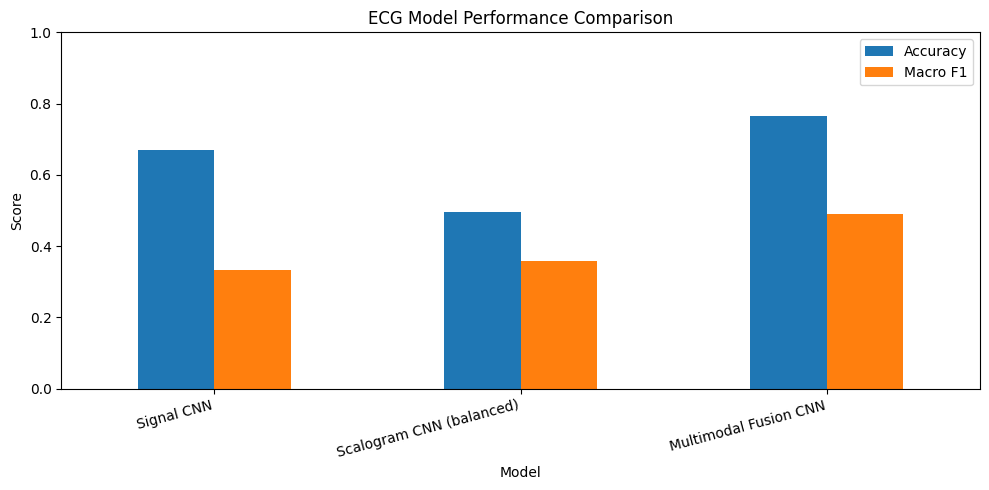

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import accuracy_score, f1_score

results = pd.DataFrame({
    "Model": [
        "Signal CNN",
        "Scalogram CNN (balanced)",
        "Multimodal Fusion CNN"
    ],
    "Accuracy": [
        accuracy_score(y_test, predictions),
        accuracy_score(y_test, img_predictions),
        accuracy_score(y_test, fusion_predictions)
    ],
    "Macro F1": [
        f1_score(y_test, predictions, average="macro", zero_division=0),
        f1_score(y_test, img_predictions, average="macro", zero_division=0),
        f1_score(y_test, fusion_predictions, average="macro", zero_division=0)
    ]
})

display(results.round(4))

results.set_index("Model")[["Accuracy", "Macro F1"]].plot(
    kind="bar", figsize=(10, 5), ylim=(0, 1)
)

plt.title("ECG Model Performance Comparison")
plt.ylabel("Score")
plt.xticks(rotation=15, ha="right")
plt.tight_layout()
plt.show()

In [ ]:
!pip install -q streamlit
!npm install -g localtunnel

⠙⠹⠸⠼⠴⠦⠧⠇⠏⠋⠙⠹⠸⠼⠴⠦⠧⠇⠏⠋⠙⠹⠸⠼⠴⠦⠧⠇⠏⠋⠙⠹
added 22 packages in 5s
⠹
⠹3 packages are looking for funding
⠹  run `npm fund` for details
⠹

In [ ]:

%%writefile /content/app.py
import streamlit as st
import pandas as pd
import matplotlib.pyplot as plt

st.set_page_config(
    page_title="Agentic Multimodal ECG Diagnosis",
    page_icon="❤️",
    layout="wide"
)

st.title("❤️ Agentic Multimodal ECG Diagnosis")
st.write(
    "Research prototype using ECG signals, scalograms, "
    "and multimodal deep learning."
)

st.warning(
    "Research demonstration only — not intended for clinical diagnosis."
)

st.header("Model Performance")

results = pd.DataFrame({
    "Model": [
        "Signal CNN",
        "Scalogram CNN (balanced)",
        "Multimodal Fusion CNN"
    ],
    "Accuracy": [0.6708, 0.4960, 0.7660],
    "Macro F1": [0.3337, 0.3583, 0.4913]
})

st.dataframe(results, use_container_width=True)

fig, ax = plt.subplots(figsize=(9, 4))
results.set_index("Model")[["Accuracy", "Macro F1"]].plot(
    kind="bar", ax=ax, ylim=(0, 1)
)
ax.set_title("ECG Model Performance Comparison")
ax.set_ylabel("Score")
ax.tick_params(axis="x", rotation=15)
fig.tight_layout()
st.pyplot(fig)

st.header("Diagnosis Workflow")

col1, col2, col3, col4 = st.columns(4)
col1.metric("Agent 1", "Preprocessing")
col2.metric("Agent 2", "Classification")
col3.metric("Agent 3", "Retrieval")
col4.metric("Agent 4", "Explanation")

st.info(
    "Next integration step: connect the trained fusion model, "
    "ECG upload, retrieval system, and explanation agent."
)

st.caption(
    "Performance figures are from a preliminary heartbeat-level "
    "test split and are not clinically validated."
)


Writing /content/app.py


In [ ]:
!streamlit run /content/app.py --server.port 8501 --server.address 0.0.0.0 > /content/streamlit.log 2>&1 &

In [ ]:
!npx localtunnel --port 8501

⠙⠹⠸⠼⠴⠦⠧your url is: https://chilly-cups-sip.loca.lt
^C


In [ ]:
!tail -30 /content/streamlit.log



2026-10-23 20:16:56.778 Port 8501 is not available
                                                                                                                                                                                           Stopping...


In [ ]:
!pkill -f streamlit

In [ ]:
!streamlit run /content/app.py --server.port 8502 --server.address 0.0.0.0 > /content/streamlit.log 2>&1 &

In [ ]:
!tail -20 /content/streamlit.log



2026-10-23 20:22:32.636 Uvicorn server started on 0.0.0.0:8502

  You can now view your Streamlit app in your browser.

  Local URL: http://localhost:8502
  Network URL: http://172.28.0.12:8502
  External URL: http://34.122.62.61:8502



In [ ]:
!npx localtunnel --port 8502

⠙⠹⠸⠼⠴⠦⠧your url is: https://twenty-windows-tie.loca.lt
^C


In [ ]:
!curl -I --max-time 10 http://127.0.0.1:8502

curl: (7) Failed to connect to 127.0.0.1 port 8502 after 0 ms: Couldn't connect to server


In [ ]:
!streamlit run /content/app.py \
  --server.port 8502 \
  --server.address 0.0.0.0 \
  --server.headless true



2026-10-23 20:25:56.563 Uvicorn server started on 0.0.0.0:8502

  You can now view your Streamlit app in your browser.

  Local URL: http://localhost:8502
  Network URL: http://172.28.0.12:8502
  External URL: http://34.122.62.61:8502

  Stopping...
  Stopping...


In [ ]:
!curl -I --max-time 10 http://127.0.0.1:8502

curl: (7) Failed to connect to 127.0.0.1 port 8502 after 0 ms: Couldn't connect to server


In [ ]:
!ps aux | grep '[s]treamlit'

In [ ]:
!nohup streamlit run /content/app.py --server.port 8502 --server.address 0.0.0.0 --server.headless true > /content/streamlit.log 2>&1 < /dev/null &

In [ ]:
!curl -I --max-time 10 http://127.0.0.1:8502

HTTP/1.1 200 OK
date: Fri, 23 Oct 2026 20:31:00 GMT
server: uvicorn
content-type: text/html; charset=utf-8
accept-ranges: bytes
content-length: 6467
last-modified: Fri, 23 Oct 2026 19:37:33 GMT
etag: "c5380f273439f6751f22d700ce5f38be"
cache-control: no-cache



In [ ]:
!wget -q https://github.com/cloudflare/cloudflared/releases/latest/download/cloudflared-linux-amd64 -O /content/cloudflared
!chmod +x /content/cloudflared

In [ ]:
!/content/cloudflared tunnel --url http://127.0.0.1:8502

2026-10-23T20:31:59Z INF Thank you for trying Cloudflare Tunnel. Doing so, without a Cloudflare account, is a quick way to experiment and try it out. However, be aware that these account-less Tunnels have no uptime guarantee, are subject to the Cloudflare Online Services Terms of Use (https://www.cloudflare.com/website-terms/), and Cloudflare reserves the right to investigate your use of Tunnels for violations of such terms. If you intend to use Tunnels in production you should use a pre-created named tunnel by following: https://developers.cloudflare.com/cloudflare-one/connections/connect-apps
2026-10-23T20:31:59Z INF Requesting new quick Tunnel on trycloudflare.com...
2026-10-23T20:32:02Z INF +--------------------------------------------------------------------------------------------+
2026-10-23T20:32:02Z INF |  Your quick Tunnel has been created! Visit it at (it may take some time to be reachable):  |
2026-10-23T20:32:02Z INF |  https://headers-native-starts-interim.trycloudflare.c

In [ ]:
!curl -I --max-time 10 http://127.0.0.1:8502

curl: (7) Failed to connect to 127.0.0.1 port 8502 after 0 ms: Couldn't connect to server


In [ ]:
!nohup /content/cloudflared tunnel --url http://127.0.0.1:8502 > /content/cloudflare.log 2>&1 < /dev/null &


In [ ]:
!sleep 5
!grep -Eo 'https://[-a-zA-Z0-9.]+\.trycloudflare\.com' /content/cloudflare.log | head -1

https://incentives-reliance-villages-col.trycloudflare.com


In [ ]:
!curl -I --max-time 10 http://127.0.0.1:8502

curl: (7) Failed to connect to 127.0.0.1 port 8502 after 0 ms: Couldn't connect to server


In [ ]:
!nohup streamlit run /content/app.py \
  --server.port 8502 \
  --server.address 0.0.0.0 \
  --server.headless true \
  > /content/streamlit.log 2>&1 < /dev/null &

In [ ]:
import time
import requests

for i in range(10):
    try:
        r = requests.get("http://127.0.0.1:8502", timeout=2)
        print("Streamlit status:", r.status_code)
        break
    except requests.RequestException:
        print("Waiting for Streamlit...")
        time.sleep(2)

Streamlit status: 200


In [ ]:
!/content/cloudflared tunnel --url http://127.0.0.1:8502

2026-10-23T20:41:40Z INF Thank you for trying Cloudflare Tunnel. Doing so, without a Cloudflare account, is a quick way to experiment and try it out. However, be aware that these account-less Tunnels have no uptime guarantee, are subject to the Cloudflare Online Services Terms of Use (https://www.cloudflare.com/website-terms/), and Cloudflare reserves the right to investigate your use of Tunnels for violations of such terms. If you intend to use Tunnels in production you should use a pre-created named tunnel by following: https://developers.cloudflare.com/cloudflare-one/connections/connect-apps
2026-10-23T20:41:40Z INF Requesting new quick Tunnel on trycloudflare.com...
2026-10-23T20:41:43Z INF +--------------------------------------------------------------------------------------------+
2026-10-23T20:41:43Z INF |  Your quick Tunnel has been created! Visit it at (it may take some time to be reachable):  |
2026-10-23T20:41:43Z INF |  https://protocol-known-bike-thomas.trycloudflare.com 

AGENTIC MULTIMODAL ECG DIAGNOSIS


,Model,Accuracy,Macro F1
0,Signal CNN,67.08%,0.3337
1,Scalogram CNN (balanced),49.60%,0.3583
2,Multimodal Fusion CNN,76.60%,0.4913


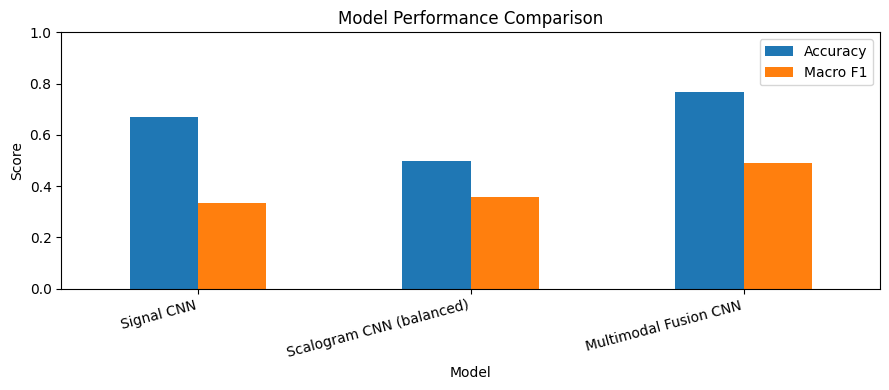

IntSlider(value=0, continuous_update=False, description='Beat index:', layout=Layout(width='80%'), max=13014)

Output()

In [ ]:

import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import torch

from IPython.display import display, clear_output
import ipywidgets as widgets
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    confusion_matrix,
    ConfusionMatrixDisplay
)

# ---------- MODEL COMPARISON ----------
results = pd.DataFrame({
    "Model": [
        "Signal CNN",
        "Scalogram CNN (balanced)",
        "Multimodal Fusion CNN"
    ],
    "Accuracy": [0.6708, 0.4960, 0.7660],
    "Macro F1": [0.3337, 0.3583, 0.4913]
})

print("AGENTIC MULTIMODAL ECG DIAGNOSIS")
print("=" * 45)
display(results.style.format({
    "Accuracy": "{:.2%}",
    "Macro F1": "{:.4f}"
}))

fig, ax = plt.subplots(figsize=(9, 4))
results.set_index("Model")[["Accuracy", "Macro F1"]].plot(
    kind="bar", ax=ax
)
ax.set_title("Model Performance Comparison")
ax.set_ylabel("Score")
ax.set_ylim(0, 1)
plt.xticks(rotation=15, ha="right")
plt.tight_layout()
plt.show()

# ---------- INTERACTIVE HEARTBEAT EXPLORER ----------
data = np.load("/content/ECG_project/beats.npz")
signals = data["signals"]
scalograms = data["scalograms"]
labels = data["labels"]

class_names = {
    0: "Normal",
    1: "Ventricular",
    2: "Supraventricular"
}

# Predict using the trained models already in memory
device = next(fusion_model.parameters()).device
fusion_model.eval()

with torch.no_grad():
    signal_tensor = torch.tensor(
        signals, dtype=torch.float32
    ).unsqueeze(1).to(device)

    image_tensor = torch.tensor(
        scalograms, dtype=torch.float32
    ).unsqueeze(1).to(device)

    # Process in batches to avoid excessive memory use
    all_predictions = []

    for start in range(0, len(signals), 256):
        end = start + 256
        logits = fusion_model(
            signal_tensor[start:end],
            image_tensor[start:end]
        )
        all_predictions.extend(
            logits.argmax(dim=1).cpu().numpy()
        )

predictions_all = np.array(all_predictions)

selector = widgets.IntSlider(
    value=0,
    min=0,
    max=len(signals)-1,
    step=1,
    description="Beat index:",
    continuous_update=False,
    layout=widgets.Layout(width="80%")
)

output = widgets.Output()

def show_beat(index):
    with output:
        clear_output(wait=True)

        fig, axes = plt.subplots(1, 2, figsize=(12, 4))

        axes[0].plot(signals[index])
        axes[0].set_title("ECG Signal")
        axes[0].set_xlabel("Sample")
        axes[0].set_ylabel("Normalized amplitude")

        axes[1].imshow(
            scalograms[index],
            aspect="auto",
            origin="lower",
            cmap="viridis"
        )
        axes[1].set_title("ECG Scalogram")
        axes[1].set_xlabel("Time")
        axes[1].set_ylabel("Scale")

        plt.tight_layout()
        plt.show()

        print("Heartbeat index:", index)
        print("Dataset label:", class_names[int(labels[index])])
        print("Fusion model prediction:",
              class_names[int(predictions_all[index])])

        print(
            "Prediction correct:",
            bool(predictions_all[index] == labels[index])
        )

selector.observe(
    lambda change: show_beat(change["new"])
    if change["name"] == "value" else None,
    names="value"
)

display(selector, output)
show_beat(0)


In [ ]:
!pip install -q gradio

In [ ]:
import gradio as gr
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch

# Load processed ECG dataset
data = np.load("/content/ECG_project/beats.npz")
signals = data["signals"]
scalograms = data["scalograms"]
labels = data["labels"]

names = {
    0: "Normal",
    1: "Ventricular",
    2: "Supraventricular"
}

device = next(fusion_model.parameters()).device
fusion_model.eval()


def diagnose(index):
    index = int(index)

    # Get the selected heartbeat's actual data
    signal = signals[index]
    image = scalograms[index]
    true_label = names[int(labels[index])]

    # Prepare inputs for the fusion model
    with torch.no_grad():
        x_signal = torch.as_tensor(
            signal, dtype=torch.float32
        ).reshape(1, 1, -1).to(device)

        x_image = torch.as_tensor(
            image, dtype=torch.float32
        ).reshape(1, 1, 64, 64).to(device)

        logits = fusion_model(x_signal, x_image)
        probabilities = torch.softmax(
            logits, dim=1
        )[0].cpu().numpy()

    predicted_class = int(np.argmax(probabilities))

    # Generate new plots for this heartbeat
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))

    axes[0].plot(np.arange(len(signal)), signal)
    axes[0].set_title(f"ECG Signal — Heartbeat {index}")
    axes[0].set_xlabel("Sample")
    axes[0].set_ylabel("Normalized amplitude")
    axes[0].grid(alpha=0.25)

    axes[1].imshow(
        image,
        aspect="auto",
        origin="lower",
        cmap="viridis"
    )
    axes[1].set_title(f"CWT Scalogram — Heartbeat {index}")
    axes[1].set_xlabel("Time")
    axes[1].set_ylabel("Scale")
    fig.tight_layout()

    # Display prediction report
    report = (
        f"Heartbeat index: {index}\n"
        f"Dataset reference label: {true_label}\n"
        f"Fusion model prediction: {names[predicted_class]}\n"
        f"Prediction confidence: "
        f"{probabilities[predicted_class] * 100:.2f}%\n\n"
        "Research prototype only — not a clinical diagnosis."
    )

    class_probabilities = {
        names[i]: float(probabilities[i])
        for i in range(3)
    }

    return fig, report, class_probabilities


comparison = pd.DataFrame({
    "Model": [
        "Signal CNN",
        "Scalogram CNN (balanced)",
        "Multimodal Fusion CNN"
    ],
    "Accuracy": [0.6708, 0.4960, 0.7660],
    "Macro F1": [0.3337, 0.3583, 0.4913]
})

with gr.Blocks(
    title="Agentic Multimodal ECG Diagnosis",
    theme=gr.themes.Soft()
) as app:

    gr.Markdown("# ❤️ Agentic Multimodal ECG Diagnosis")
    gr.Markdown(
        "Explore ECG heartbeats, view their scalograms, "
        "and examine experimental model predictions."
    )

    gr.Markdown("## Model Performance Comparison")
    gr.Dataframe(
        value=comparison,
        interactive=False
    )

    gr.Markdown("## Heartbeat Analysis")

    index = gr.Slider(
        minimum=0,
        maximum=len(signals) - 1,
        value=0,
        step=1,
        label="Select heartbeat"
    )

    analyze = gr.Button(
        "Analyze Heartbeat",
        variant="primary"
    )

    plot = gr.Plot(label="ECG Signal and CWT Scalogram")
    report = gr.Textbox(
        label="Prediction Report",
        lines=5
    )
    probabilities = gr.Label(
        label="Model Class Probabilities",
        num_top_classes=3
    )

    # Update plots and prediction when the button is clicked
    analyze.click(
        fn=diagnose,
        inputs=index,
        outputs=[plot, report, probabilities]
    )

    # Also update automatically when the slider changes
    index.change(
        fn=diagnose,
        inputs=index,
        outputs=[plot, report, probabilities]
    )

    gr.Markdown(
        "**Research use only.** Experimental predictions "
        "must not be used for medical decisions."
    )

app.launch(share=True, debug=False)

/tmp/ipykernel_3800/277478231.py:96: UserWarning: The parameters have been moved from the Blocks constructor to the launch() method in Gradio 6.0: theme. Please pass these parameters to launch() instead.
  with gr.Blocks(


Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://1874042e3201a9bad3.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


In [ ]:

print("Fusion model:", "fusion_model" in globals())
print("Scalogram model:", "scalogram_model" in globals())
import os
import gradio as gr
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn.functional as F
from pathlib import Path
from datetime import datetime

# ---------------- DATA ----------------
PROJECT = "/content/ECG_project"
data = np.load(f"{PROJECT}/beats.npz")

signals = data["signals"]
scalograms = data["scalograms"]
labels = data["labels"]

NAMES = {
    0: "Normal",
    1: "Ventricular",
    2: "Supraventricular"
}

device = next(fusion_model.parameters()).device
fusion_model.eval()
scalogram_model.eval()

comparison = pd.DataFrame({
    "Model": [
        "Signal CNN",
        "Scalogram CNN (balanced)",
        "Multimodal Fusion CNN"
    ],
    "Accuracy": [0.6708, 0.4960, 0.7660],
    "Macro F1": [0.3337, 0.3583, 0.4913]
})

# ---------------- PREDICTION ----------------
def predict_heartbeat(index):
    index = int(index)
    signal = signals[index]
    image = scalograms[index]

    xs = torch.tensor(
        signal, dtype=torch.float32
    ).reshape(1, 1, -1).to(device)

    xi = torch.tensor(
        image, dtype=torch.float32
    ).reshape(1, 1, 64, 64).to(device)

    with torch.no_grad():
        logits = fusion_model(xs, xi)
        probs = torch.softmax(logits, dim=1)[0].cpu().numpy()

    pred = int(np.argmax(probs))

    return signal, image, pred, probs


# ---------------- 1. HEARTBEAT EXPLORER ----------------
def heartbeat_explorer(index):
    index = int(index)
    signal, image, pred, probs = predict_heartbeat(index)

    fig, axes = plt.subplots(1, 2, figsize=(12, 4))

    axes[0].plot(signal)
    axes[0].set_title(f"ECG Signal — Beat {index}")
    axes[0].set_xlabel("Sample")
    axes[0].set_ylabel("Normalized amplitude")
    axes[0].grid(alpha=0.25)

    im = axes[1].imshow(
        image, aspect="auto", origin="lower", cmap="viridis"
    )
    axes[1].set_title(f"CWT Scalogram — Beat {index}")
    axes[1].set_xlabel("Time")
    axes[1].set_ylabel("Scale")
    fig.colorbar(im, ax=axes[1], fraction=0.046)

    fig.tight_layout()

    report = (
        f"Heartbeat index: {index}\n"
        f"Reference label: {NAMES[int(labels[index])]}\n"
        f"Fusion prediction: {NAMES[pred]}\n"
        f"Prediction confidence: {probs[pred]*100:.2f}%\n"
        f"Reference match: {pred == int(labels[index])}\n\n"
        "Research prototype only; not a clinical diagnosis."
    )

    scores = {NAMES[i]: float(probs[i]) for i in range(3)}
    return fig, report, scores


# ---------------- 2. MODEL COMPARISON ----------------
def compare_models():
    fig, ax = plt.subplots(figsize=(9, 4))
    comparison.set_index("Model")[["Accuracy", "Macro F1"]].plot(
        kind="bar", ax=ax
    )
    ax.set_ylim(0, 1)
    ax.set_ylabel("Score")
    ax.set_title("Model Performance Comparison")
    ax.tick_params(axis="x", rotation=15)
    fig.tight_layout()
    return comparison, fig


# ---------------- 3. SIGNAL QUALITY ----------------
def signal_quality(index):
    index = int(index)
    x = signals[index].astype(float)

    amplitude_range = float(np.ptp(x))
    std_dev = float(np.std(x))
    flat_fraction = float(np.mean(np.abs(np.diff(x)) < 1e-6))

    # Simple screening indicators, not clinical signal-quality scores
    warnings = []
    if not np.all(np.isfinite(x)):
        warnings.append("Non-finite values detected.")
    if std_dev < 1e-5:
        warnings.append("Signal has very low variation.")
    if flat_fraction > 0.2:
        warnings.append("Many adjacent samples are nearly identical.")

    status = (
        "Review recommended: " + " ".join(warnings)
        if warnings else
        "No basic numerical quality flags detected."
    )

    fig, ax = plt.subplots(figsize=(9, 3))
    ax.plot(x)
    ax.set_title(f"Signal Quality View — Beat {index}")
    ax.set_xlabel("Sample")
    ax.set_ylabel("Normalized amplitude")
    ax.grid(alpha=0.25)
    fig.tight_layout()

    table = pd.DataFrame({
        "Measure": [
            "Number of samples",
            "Minimum amplitude",
            "Maximum amplitude",
            "Amplitude range",
            "Standard deviation",
            "Nearly identical adjacent sample fraction"
        ],
        "Value": [
            len(x), float(x.min()), float(x.max()),
            amplitude_range, std_dev, flat_fraction
        ]
    })

    return fig, table, status


# ---------------- 4. EXPLAINABLE AI: GRAD-CAM ----------------
def scalogram_gradcam(index):
    index = int(index)
    image = scalograms[index]

    # This implementation expects the existing ScalogramCNN
    # to contain a self.features sequential module.
    target_layer = None
    for layer in scalogram_model.features.modules():
        if isinstance(layer, torch.nn.Conv2d):
            target_layer = layer

    if target_layer is None:
        return None, (
            "Grad-CAM unavailable: no Conv2d layer was found "
            "in scalogram_model.features."
        )

    activations = {}
    gradients = {}

    def forward_hook(module, inputs, output):
        activations["value"] = output

    def backward_hook(module, grad_input, grad_output):
        gradients["value"] = grad_output[0]

    h1 = target_layer.register_forward_hook(forward_hook)
    h2 = target_layer.register_full_backward_hook(backward_hook)

    try:
        x = torch.tensor(
            image, dtype=torch.float32
        ).reshape(1, 1, 64, 64).to(device)
        x.requires_grad_(True)

        scalogram_model.zero_grad(set_to_none=True)
        logits = scalogram_model(x)
        predicted = logits.argmax(dim=1)
        logits[0, predicted.item()].backward()

        acts = activations["value"].detach()
        grads = gradients["value"].detach()

        weights = grads.mean(dim=(2, 3), keepdim=True)
        cam = (weights * acts).sum(dim=1, keepdim=True)
        cam = F.relu(cam)
        cam = F.interpolate(
            cam, size=(64, 64),
            mode="bilinear", align_corners=False
        )[0, 0].cpu().numpy()

        cam = (cam - cam.min()) / (cam.max() - cam.min() + 1e-8)

        fig, axes = plt.subplots(1, 2, figsize=(9, 4))
        axes[0].imshow(image, origin="lower", aspect="auto", cmap="viridis")
        axes[0].set_title("Original Scalogram")
        axes[1].imshow(image, origin="lower", aspect="auto", cmap="gray")
        axes[1].imshow(cam, origin="lower", aspect="auto",
                       cmap="jet", alpha=0.45)
        axes[1].set_title("Grad-CAM Overlay")
        fig.tight_layout()

        return fig, (
            f"Scalogram CNN predicted: {NAMES[int(predicted.item())]}\n"
            "Grad-CAM highlights regions that influenced this model's output. "
            "It does not establish medical causation."
        )
    except Exception as exc:
        return None, f"Grad-CAM could not be generated: {exc}"
    finally:
        h1.remove()
        h2.remove()


# ---------------- 5. DOWNLOADABLE REPORT ----------------
def create_report(index):
    index = int(index)
    signal, image, pred, probs = predict_heartbeat(index)

    os.makedirs(f"{PROJECT}/reports", exist_ok=True)
    filename = f"{PROJECT}/reports/ecg_report_{index}.txt"

    with open(filename, "w", encoding="utf-8") as f:
        f.write("AGENTIC MULTIMODAL ECG ANALYSIS REPORT\n")
        f.write("=" * 42 + "\n")
        f.write(f"Generated: {datetime.now().isoformat(timespec='seconds')}\n")
        f.write(f"Heartbeat index: {index}\n")
        f.write(f"Reference label: {NAMES[int(labels[index])]}\n")
        f.write(f"Fusion prediction: {NAMES[pred]}\n")
        f.write(f"Prediction matches reference: {pred == int(labels[index])}\n\n")
        f.write("Class probabilities:\n")
        for i in range(3):
            f.write(f"- {NAMES[i]}: {probs[i]*100:.2f}%\n")
        f.write("\nModel comparison:\n")
        f.write(comparison.to_string(index=False))
        f.write(
            "\n\nLIMITATION: Experimental research output only. "
            "Not a clinical diagnosis."
        )

    return filename


# ---------------- 6. AGENT WORKFLOW VISUALIZATION ----------------
def run_workflow(index):
    index = int(index)

    # Preprocessing and classification are executed using the existing data/model.
    signal, image, pred, probs = predict_heartbeat(index)

    workflow = pd.DataFrame({
        "Stage": [
            "Preprocessing",
            "Classification",
            "Retrieval",
            "Explanation"
        ],
        "Status": [
            "Completed: processed heartbeat loaded",
            "Completed: fusion prediction generated",
            "Not implemented: no retrieval index connected",
            "Partial: prediction probabilities available; Grad-CAM separate"
        ],
        "Output": [
            f"{len(signal)} signal samples; scalogram {image.shape}",
            NAMES[pred],
            "No retrieved references",
            f"Top class probability {probs[pred]*100:.2f}%"
        ]
    })

    fig, ax = plt.subplots(figsize=(10, 2.5))
    ax.axis("off")

    stages = ["Preprocessing", "Classification", "Retrieval", "Explanation"]
    for i, stage in enumerate(stages):
        ax.text(
            i, 0.5, stage, ha="center", va="center",
            bbox=dict(boxstyle="round,pad=0.6", fc="#e7f3ff", ec="#3675a9")
        )
        if i < len(stages)-1:
            ax.annotate("", xy=(i+0.65, 0.5), xytext=(i+0.35, 0.5),
                        arrowprops=dict(arrowstyle="->", lw=1.5))
    ax.set_xlim(-0.5, 3.5)
    ax.set_ylim(0, 1)
    fig.tight_layout()

    return fig, workflow


# ---------------- GRADIO INTERFACE ----------------
with gr.Blocks(
    title="Agentic Multimodal ECG Diagnosis",
    theme=gr.themes.Soft()
) as app:

    gr.Markdown("# ❤️ Agentic Multimodal ECG Diagnosis")
    gr.Markdown(
        "Interactive research prototype for ECG heartbeat classification "
        "using signal and scalogram fusion."
    )
    gr.Markdown(
        "**Research use only. Predictions are experimental and must not "
        "be used for medical decisions.**"
    )

    with gr.Tab("1. Heartbeat Explorer"):
        heartbeat_index = gr.Slider(
            0, len(signals)-1, value=0, step=1,
            label="Select heartbeat"
        )
        heartbeat_button = gr.Button("Analyze heartbeat", variant="primary")
        heartbeat_plot = gr.Plot(label="ECG Signal and Scalogram")
        heartbeat_report = gr.Textbox(label="Prediction Report", lines=5)
        heartbeat_scores = gr.Label(label="Fusion Model Probabilities")

        heartbeat_button.click(
            heartbeat_explorer,
            inputs=heartbeat_index,
            outputs=[heartbeat_plot, heartbeat_report, heartbeat_scores]
        )
        heartbeat_index.change(
            heartbeat_explorer,
            inputs=heartbeat_index,
            outputs=[heartbeat_plot, heartbeat_report, heartbeat_scores]
        )

    with gr.Tab("2. Model Comparison"):
        compare_button = gr.Button("Show comparison")
        compare_table = gr.Dataframe(value=comparison)
        compare_plot = gr.Plot()
        compare_button.click(
            compare_models, outputs=[compare_table, compare_plot]
        )

    with gr.Tab("3. Signal Quality"):
        quality_index = gr.Slider(
            0, len(signals)-1, value=0, step=1,
            label="Select heartbeat"
        )
        quality_button = gr.Button("Analyze signal quality")
        quality_plot = gr.Plot()
        quality_table = gr.Dataframe()
        quality_status = gr.Textbox(label="Quality screening result")
        quality_button.click(
            signal_quality,
            inputs=quality_index,
            outputs=[quality_plot, quality_table, quality_status]
        )

    with gr.Tab("4. Explainable AI"):
        gradcam_index = gr.Slider(
            0, len(signals)-1, value=0, step=1,
            label="Select heartbeat"
        )
        gradcam_button = gr.Button("Generate Grad-CAM")
        gradcam_plot = gr.Plot()
        gradcam_report = gr.Textbox(label="Explanation")
        gradcam_button.click(
            scalogram_gradcam,
            inputs=gradcam_index,
            outputs=[gradcam_plot, gradcam_report]
        )

    with gr.Tab("5. Download Report"):
        report_index = gr.Slider(
            0, len(signals)-1, value=0, step=1,
            label="Select heartbeat"
        )
        report_button = gr.Button("Generate report")
        report_file = gr.File(label="Download analysis report")
        report_button.click(
            create_report, inputs=report_index, outputs=report_file
        )

    with gr.Tab("6. Agent Workflow"):
        workflow_index = gr.Slider(
            0, len(signals)-1, value=0, step=1,
            label="Select heartbeat"
        )
        workflow_button = gr.Button("Run workflow view")
        workflow_plot = gr.Plot()
        workflow_table = gr.Dataframe()
        workflow_button.click(
            run_workflow,
            inputs=workflow_index,
            outputs=[workflow_plot, workflow_table]
        )

app.launch(share=True, debug=False)


Fusion model: True
Scalogram model: True


/tmp/ipykernel_3800/1739237553.py:316: UserWarning: The parameters have been moved from the Blocks constructor to the launch() method in Gradio 6.0: theme. Please pass these parameters to launch() instead.
  with gr.Blocks(


Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://741498ed6787c800c3.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


In [ ]:
!python /content/app.py

Traceback (most recent call last):
  File "/content/app.py", line 25, in <module>
    device = next(fusion_model.parameters()).device
                  ^^^^^^^^^^^^
NameError: name 'fusion_model' is not defined
